# Model Interpretability with Captum

In [1]:
import torch
import torch.nn.functional as F 
import torchvision.transforms as transforms
import torchvision.models as models

import captum
from captum.attr import  IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution
from captum.attr import visualization as viz 

import os, sys
import json


import numpy as np 
from PIL import Image
import matplotlib.pyplot as plt 
from matplotlib.colors import LinearSegmentedColormap

/Users/saleh/Desktop/Pytorch/Codes/pytorch/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model = models.resnet101(pretrained=True)
model= model.eval()

/Users/saleh/Desktop/Pytorch/Codes/pytorch/venv/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/saleh/Desktop/Pytorch/Codes/pytorch/venv/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


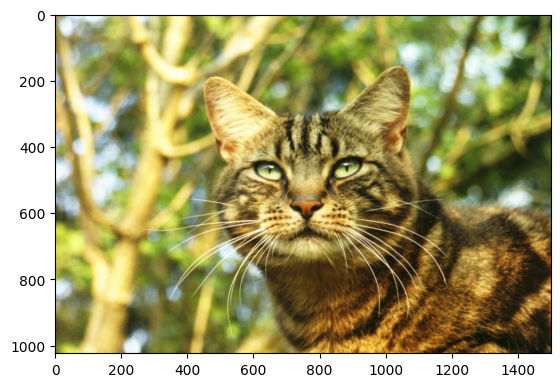

In [3]:
test_image= Image.open("img/cat.jpg")
test_image_date= np.asarray(test_image)
plt.imshow(test_image_date)
plt.show()

In [4]:
transform= transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
])

In [5]:
transform_normalize=transforms.Normalize(mean=[0.485,0.456, 0.406], 
                                        std=[0.229,0.224,0.225])

In [6]:
transformed_img= transform(test_image)
input_img= transform_normalize(transformed_img)
input_img= input_img.unsqueeze(0)

In [7]:
label_path= "img/imagenet_class_index.json"
with open(label_path) as json_data:
    idx_to_labels= json.load(json_data)

In [8]:
output= model(input_img)
output= F.softmax(output, dim=1)
prediction_score, pred_label_idx= torch.topk(output, 1)
pred_label_idx.squeeze_()
prediction_label= idx_to_labels[str(pred_label_idx.item())][1]
print("Prediction:", prediction_label, "(", prediction_score.squeeze().item(), ")")

Prediction: tabby ( 0.6249911785125732 )


In [9]:
intergrated_gradient= IntegratedGradients(model)
attribution_ig= intergrated_gradient.attribute(input_img, target= pred_label_idx, n_steps= 200)

Image shape: (224, 224, 3)
Attribution shape: (224, 224, 3)


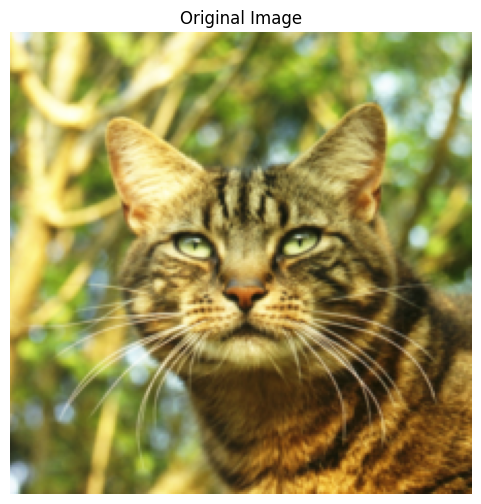

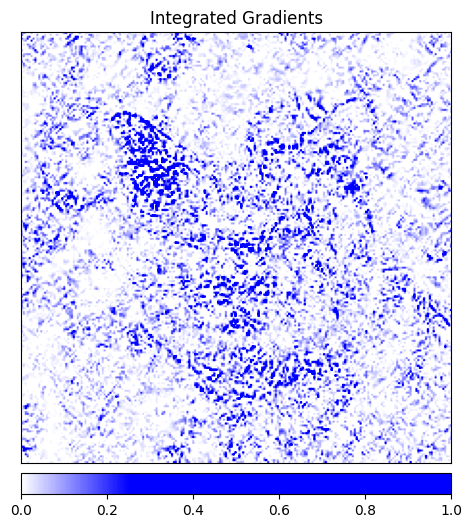

In [15]:
# Convert the image tensor to NumPy
image_np = transformed_img.detach().cpu().numpy()

# Remove batch dimension
if image_np.ndim == 4:
    image_np = image_np[0]

# Convert (C, H, W) to (H, W, C)
image_np = np.transpose(image_np, (1, 2, 0))

# Convert Integrated Gradients attributions to NumPy
attr_np = attribution_ig.detach().cpu().numpy()

# Remove batch dimension
if attr_np.ndim == 4:
    attr_np = attr_np[0]

# Convert (C, H, W) to (H, W, C)
attr_np = np.transpose(attr_np, (1, 2, 0))

print("Image shape:", image_np.shape)
print("Attribution shape:", attr_np.shape)

# --------------------------------------------------
# 1. Display the original image using Matplotlib
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 6))

display_image = image_np 
display_image = np.clip(display_image, 0, 1)

ax.imshow(display_image)
ax.set_title("Original Image")
ax.axis("off")

plt.show()

# --------------------------------------------------
# 2. Display Integrated Gradients heatmap
# --------------------------------------------------

default_cmap = LinearSegmentedColormap.from_list(
    "custom blue",
    [
        (0, "#ffffff"),
        (0.25, "#0000ff"),
        (1, "#0000ff")
    ],
    N=256
)

_ = viz.visualize_image_attr(
    attr_np,
    display_image,
    method="heat_map",
    cmap=default_cmap,
    show_colorbar=True,
    sign="positive",
    title="Integrated Gradients"
)

plt.show()

In [16]:
occlusion = Occlusion(model)

attributions_occ = occlusion.attribute(input_img,
                                       target=pred_label_idx,
                                       strides=(3, 8, 8),
                                       sliding_window_shapes=(3,15, 15),
                                       baselines=0)


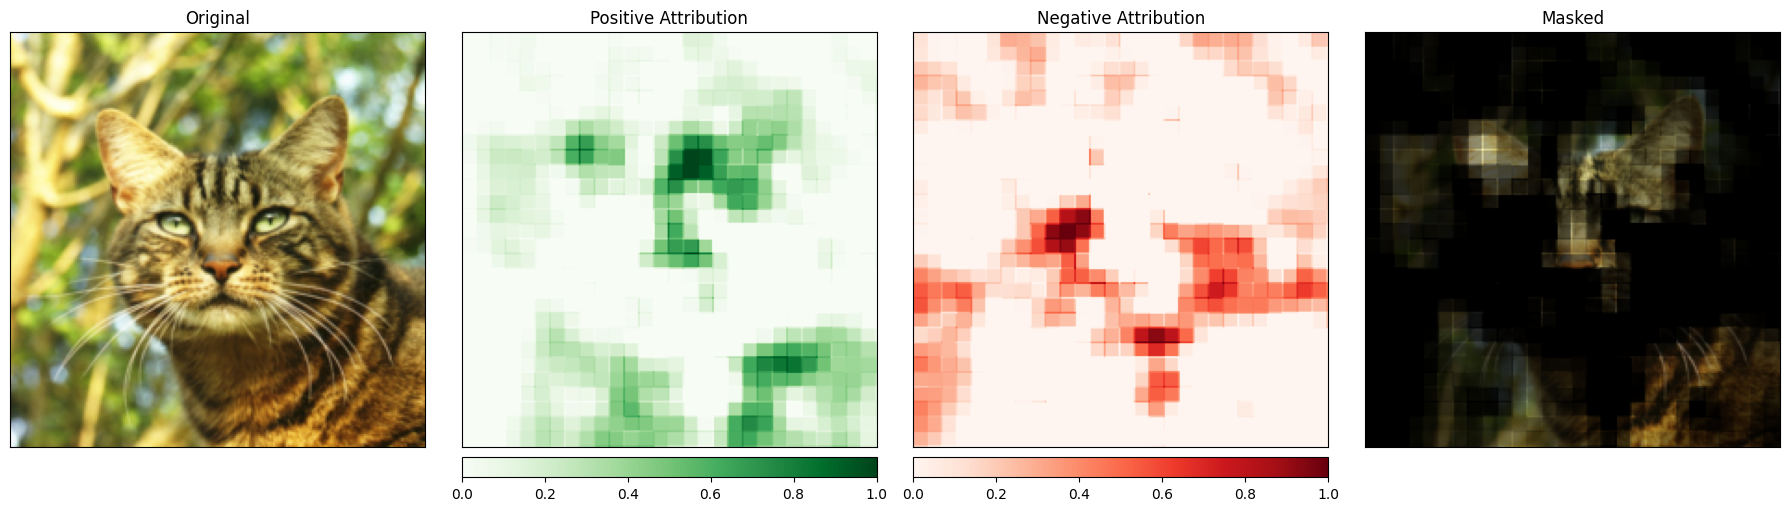

In [17]:
_ = viz.visualize_image_attr_multiple(np.transpose(attributions_occ.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      np.transpose(transformed_img.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      ["original_image", "heat_map", "heat_map", "masked_image"],
                                      ["all", "positive", "negative", "positive"],
                                      show_colorbar=True,
                                      titles=["Original", "Positive Attribution", "Negative Attribution", "Masked"],
                                      fig_size=(18, 6)
                                     )

In [18]:
layer_gradcam = LayerGradCam(model, model.layer3[1].conv2)
attributions_lgc = layer_gradcam.attribute(input_img, target=pred_label_idx)

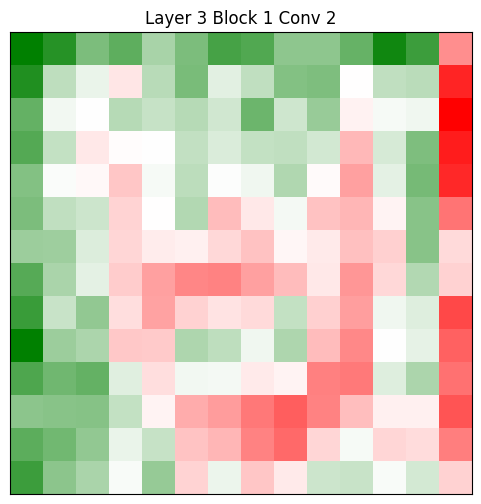

In [19]:
_ = viz.visualize_image_attr(attributions_lgc[0].cpu().permute(1,2,0).detach().numpy(),
                             sign="all",
                             title="Layer 3 Block 1 Conv 2")

torch.Size([1, 1, 14, 14])
torch.Size([1, 1, 224, 224])
torch.Size([1, 3, 224, 224])


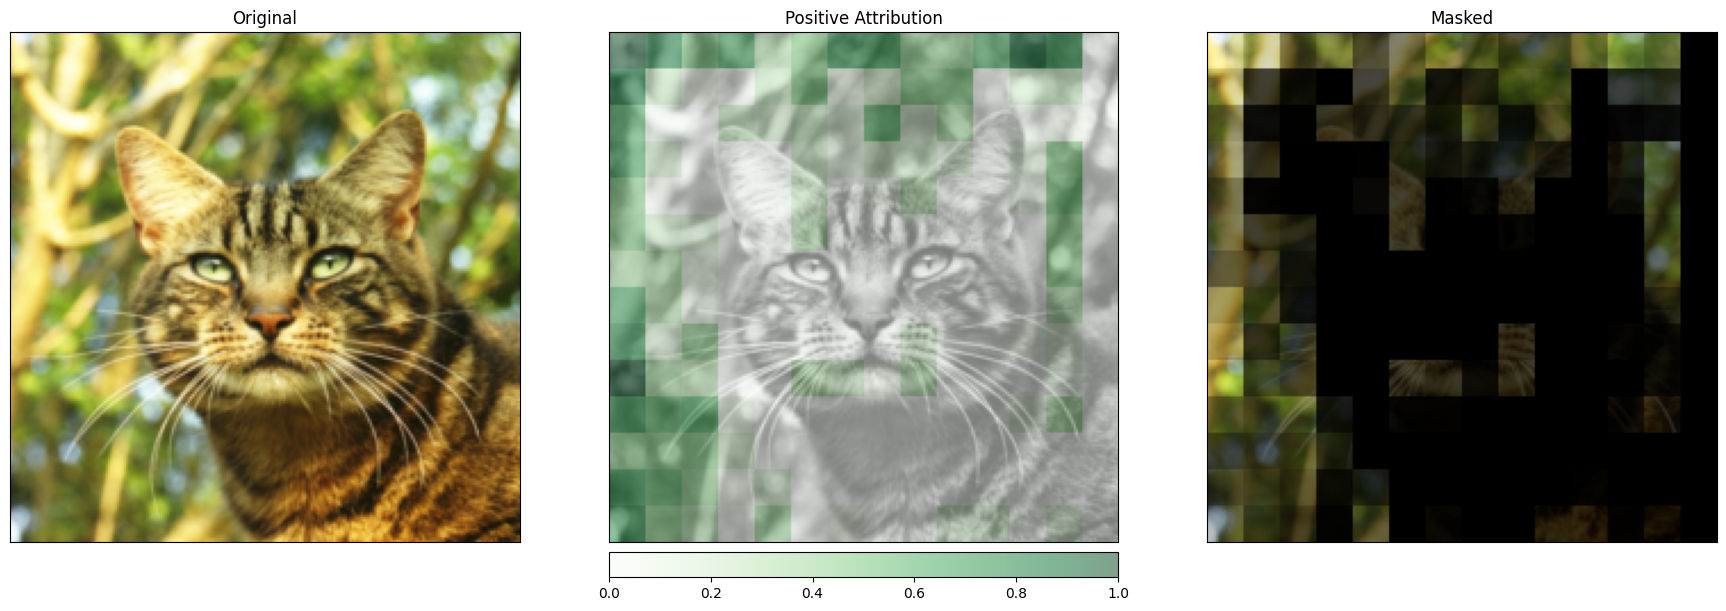

In [20]:
upsamp_attr_lgc = LayerAttribution.interpolate(attributions_lgc, input_img.shape[2:])

print(attributions_lgc.shape)
print(upsamp_attr_lgc.shape)
print(input_img.shape)

_ = viz.visualize_image_attr_multiple(upsamp_attr_lgc[0].cpu().permute(1,2,0).detach().numpy(),
                                      transformed_img.permute(1,2,0).numpy(),
                                      ["original_image","blended_heat_map","masked_image"],
                                      ["all","positive","positive"],
                                      show_colorbar=True,
                                      titles=["Original", "Positive Attribution", "Masked"],
                                      fig_size=(18, 6))

In [21]:
imgs = ['img/cat.jpg', 'img/teapot.jpg', 'img/trilobite.jpg']

for img in imgs:
    img = Image.open(img)
    transformed_img = transform(img)
    input_img = transform_normalize(transformed_img)
    input_img = input_img.unsqueeze(0) # the model requires a dummy batch dimension

    output = model(input_img)
    output = F.softmax(output, dim=1)
    prediction_score, pred_label_idx = torch.topk(output, 1)
    pred_label_idx.squeeze_()
    predicted_label = idx_to_labels[str(pred_label_idx.item())][1]
    print('Predicted:', predicted_label, '/', pred_label_idx.item(), ' (', prediction_score.squeeze().item(), ')')

Predicted: tabby / 281  ( 0.6249911785125732 )
Predicted: teapot / 849  ( 0.9153441190719604 )
Predicted: trilobite / 69  ( 0.9995917677879333 )


In [23]:
from captum.insights import AttributionVisualizer, Batch
from captum.insights.attr_vis.features import ImageFeature

# Baseline is all-zeros input - this may differ depending on your data
def baseline_func(input):
    return input * 0

# merging our image transforms from above
def full_img_transform(input):
    i = Image.open(input)
    i = transform(i)
    i = transform_normalize(i)
    i = i.unsqueeze(0)
    return i


input_imgs = torch.cat(list(map(lambda i: full_img_transform(i), imgs)), 0)

visualizer = AttributionVisualizer(
    models=[model],
    score_func=lambda o: torch.nn.functional.softmax(o, 1),
    classes=list(map(lambda k: idx_to_labels[k][1], idx_to_labels.keys())),
    features=[
        ImageFeature(
            "Photo",
            baseline_transforms=[baseline_func],
            input_transforms=[],
        )
    ],
    dataset=[Batch(input_imgs, labels=[282,849,69])]
)

In [ ]:
visualizer.render()